# CV Phase 9 — Image preprocessing

This notebook interactively inspects the immutable patient-level SMC-LUD split. It reuses `liversira_ai.cv.data.preprocessing` and displays validation and visual comparisons inline. No preprocessed images, reports, or figures are written to disk.

## Imports and configuration

In [1]:
import hashlib
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import torch

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (candidate / "src" / "liversira_ai").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing 'src/liversira_ai'."
    )

ROOT = PROJECT_ROOT
SRC_DIR = ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from liversira_ai.common.paths import CV_PROCESSED_DIR, CV_RAW_DIR
from liversira_ai.cv.data.preprocessing import (
    IMAGENET_MEAN,
    IMAGENET_STD,
    LABELS,
    SPLITS,
    PreprocessingConfig,
    SMCLUDDataset,
    create_dataloader,
    image_to_tensor,
    load_image,
    normalize_tensor,
    resize_image,
)

DATASET_ROOT = CV_PROCESSED_DIR / "patient_split_v1"
config = PreprocessingConfig((512, 512), "letterbox", normalization="imagenet")

## Input inspection and image validation

In [2]:
metadata = pd.read_csv(DATASET_ROOT / 'patient_split_metadata.csv')
metadata['path'] = metadata['destination_rel_path'].map(lambda value: DATASET_ROOT / value)
metadata['exists'] = metadata['path'].map(Path.is_file)
metadata['source_path'] = metadata['source_rel_path'].map(lambda value: CV_RAW_DIR / value)
metadata['source_exists'] = metadata['source_path'].map(Path.is_file)

dimensions = []
invalid = []
for row in metadata.itertuples():
    try:
        image = load_image(row.path)
        dimensions.append((row.split, row.label, image.width, image.height, image.mode))
    except Exception as exc:
        invalid.append({'path': str(row.path), 'error': str(exc)})

dimension_table = pd.DataFrame(dimensions, columns=['split', 'label', 'width', 'height', 'mode'])
display(metadata.groupby(['split', 'label']).size().rename('count').to_frame())
display(dimension_table.groupby(['width', 'height', 'mode']).size().rename('count').reset_index().head(20))
print({'total': len(metadata), 'readable': len(dimensions), 'invalid': len(invalid), 'rgb_after_load': (dimension_table['mode'] == 'RGB').all()})
invalid[:5]

count
split label            
test  HCC           127
      Hemangioma    130
train HCC           930
      Hemangioma    840
val   HCC           332
      Hemangioma    297

,width,height,mode,count
0,353,457,RGB,1
1,356,473,RGB,1
2,456,348,RGB,27
3,512,512,RGB,1389
4,610,553,RGB,9
5,611,570,RGB,1
6,616,601,RGB,1
7,624,610,RGB,1
8,637,532,RGB,2
9,656,652,RGB,4


{'total': 2656, 'readable': 2656, 'invalid': 0, 'rgb_after_load': np.True_}


[]

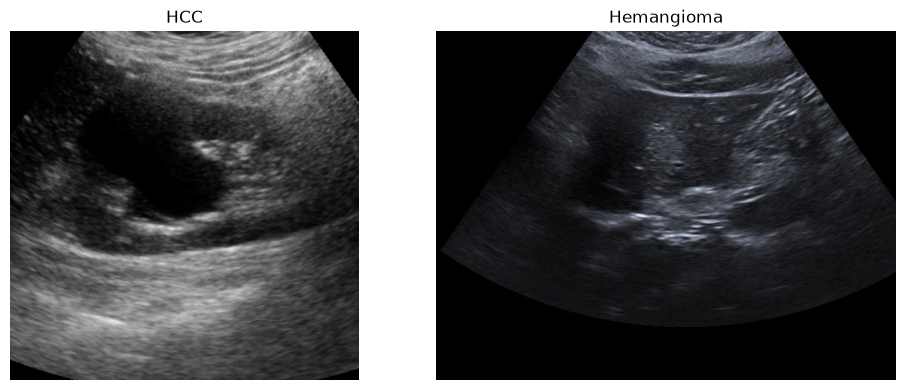

In [3]:
samples = [
    ('HCC', sorted((DATASET_ROOT / 'train' / 'HCC').glob('*'))[0]),
    ('Hemangioma', sorted((DATASET_ROOT / 'train' / 'Hemangioma').glob('*'))[0]),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, (label, path) in zip(axes, samples):
    axis.imshow(load_image(path))
    axis.set_title(label)
    axis.axis('off')
plt.tight_layout()
plt.show()

## Direct resize versus letterbox

HCC 003b4bfc-343d-4d00-8445-bfcfe7e6dede.png


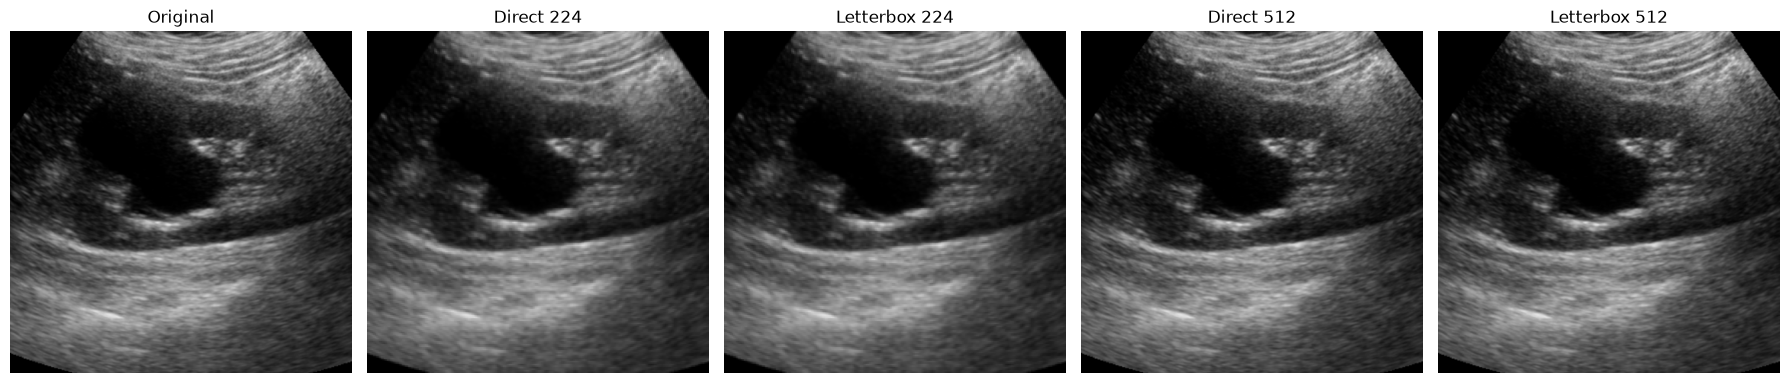

Hemangioma 00afcf6d-6eaa-4e3d-8024-735fe96b62ea.jpg


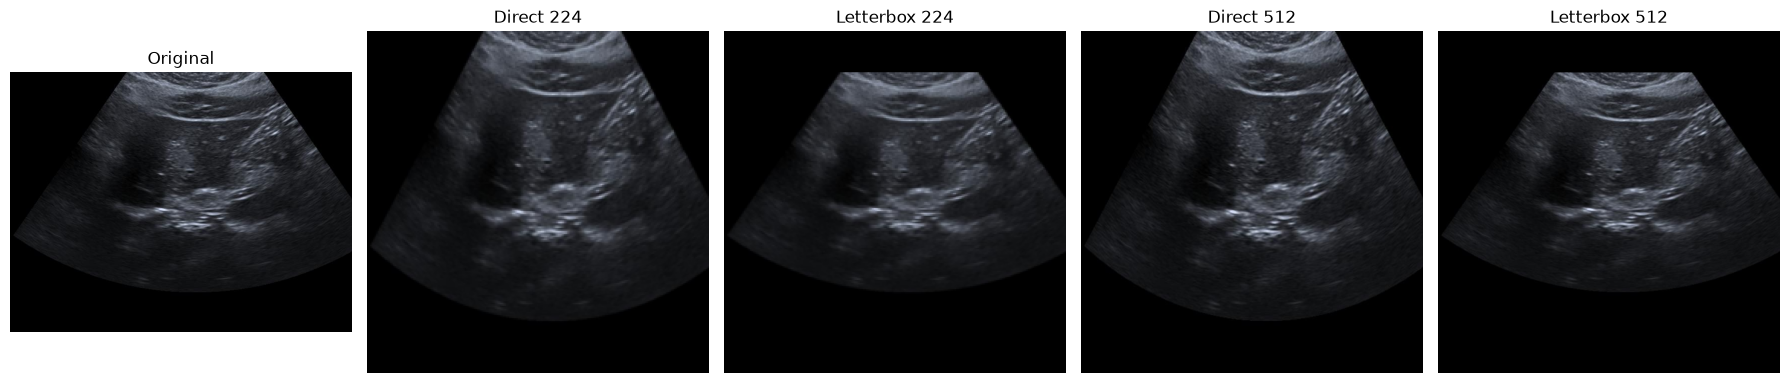

In [4]:
def show_resize_comparison(path):
    original = load_image(path)
    variants = [
        ('Original', original),
        ('Direct 224', resize_image(original, PreprocessingConfig((224, 224), 'direct'))),
        ('Letterbox 224', resize_image(original, PreprocessingConfig((224, 224), 'letterbox'))),
        ('Direct 512', resize_image(original, PreprocessingConfig((512, 512), 'direct'))),
        ('Letterbox 512', resize_image(original, PreprocessingConfig((512, 512), 'letterbox'))),
    ]
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for axis, (title, image) in zip(axes, variants):
        axis.imshow(image)
        axis.set_title(title)
        axis.axis('off')
    plt.tight_layout()
    plt.show()

for label, path in samples:
    print(label, path.name)
    show_resize_comparison(path)

## Visual review and preprocessing decision

The first examples above are useful for checking readability, but the decision must also include a non-square source because direct resizing only changes geometry in that case. The next cell deliberately compares one square HCC image and one non-square Hemangioma image. Review the lesion boundary, acoustic shadowing, liver texture, and probe sector geometry before accepting the decision below.

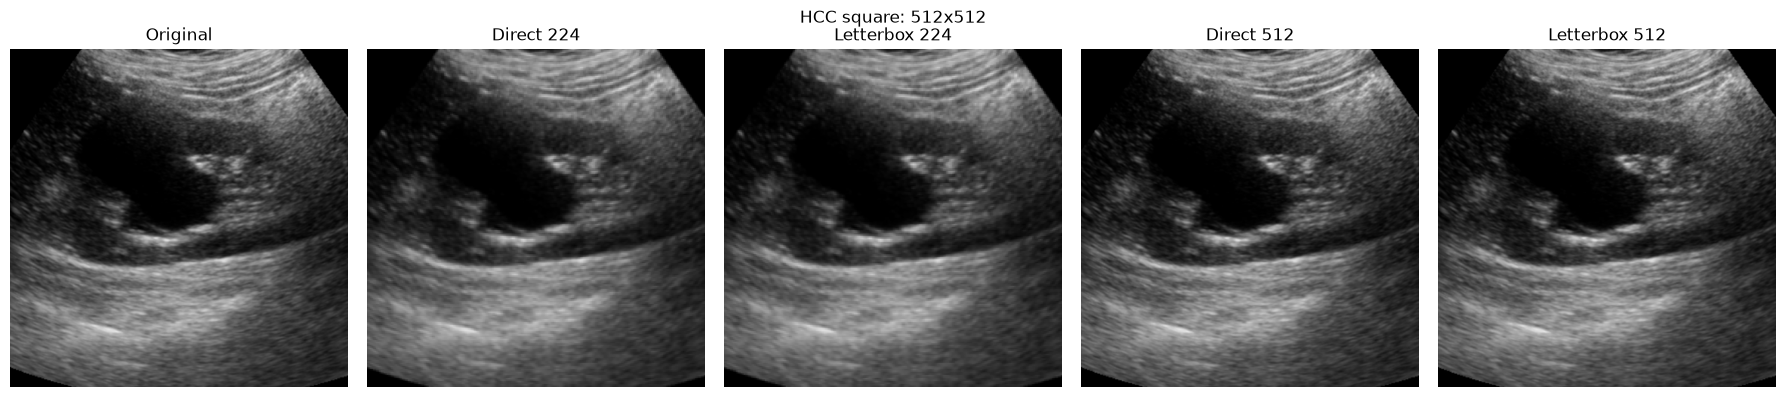

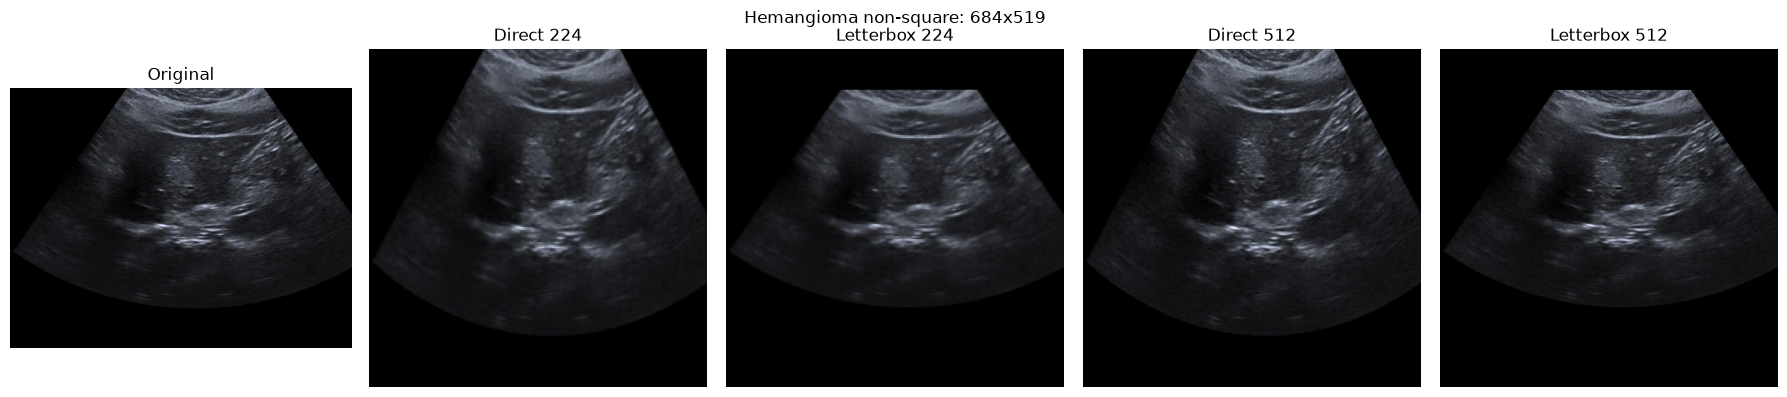

,sample,file,original_size,aspect_ratio
0,HCC square,003b4bfc-343d-4d00-8445-bfcfe7e6dede.png,"(512, 512)",1.000
1,Hemangioma non-square,00afcf6d-6eaa-4e3d-8024-735fe96b62ea.jpg,"(684, 519)",1.318


In [5]:
review_samples = [
    ("HCC square", next(path for path in sorted((DATASET_ROOT / "train" / "HCC").glob("*")) if load_image(path).width == load_image(path).height)),
    ("Hemangioma non-square", next(path for path in sorted((DATASET_ROOT / "train" / "Hemangioma").glob("*")) if load_image(path).width != load_image(path).height)),
]

review_rows = []
for label, path in review_samples:
    original = load_image(path)
    review_rows.append({"sample": label, "file": path.name, "original_size": original.size, "aspect_ratio": round(original.width / original.height, 3)})
    variants = [
        ("Original", original),
        ("Direct 224", resize_image(original, PreprocessingConfig((224, 224), "direct"))),
        ("Letterbox 224", resize_image(original, PreprocessingConfig((224, 224), "letterbox"))),
        ("Direct 512", resize_image(original, PreprocessingConfig((512, 512), "direct"))),
        ("Letterbox 512", resize_image(original, PreprocessingConfig((512, 512), "letterbox"))),
    ]
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for axis, (title, image) in zip(axes, variants):
        axis.imshow(image)
        axis.set_title(title)
        axis.axis("off")
    fig.suptitle(f"{label}: {original.size[0]}x{original.size[1]}")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(review_rows))

### Decision for the next CV phase

- **Input size: 512x512.** The 512 views retain finer lesion margins and texture; 224 remains available for a later explicitly controlled ablation.
- **Resize: Letterbox.** The non-square comparison shows that direct resize changes the sector geometry, while letterbox preserves the original aspect ratio and does not crop structures.
- **Normalization: ImageNet mean/std.** This remains the baseline for future ResNet50/EfficientNet transfer-learning experiments. It changes channel intensity scale, not spatial anatomy; it is not a substitute for visual review.
- **Visual quality:** the main structures remain visible after letterboxing. Padding is black and confined to the unused dimension; no center crop is applied.

These are the Phase 9 baseline settings, not a claim that 512 is universally optimal. Any 224 comparison in Phase 10 should be a declared experiment using the same split and evaluation protocol.

## Tensor conversion and normalization

In [6]:
image = load_image(samples[0][1])
resized = resize_image(image, config)
before = image_to_tensor(resized)
after = normalize_tensor(before, "imagenet")
tensor_checks = {
    "shape": tuple(before.shape),
    "dtype": str(before.dtype),
    "before_min": float(before.min()),
    "before_max": float(before.max()),
    "before_finite": bool(torch.isfinite(before).all()),
    "after_finite": bool(torch.isfinite(after).all()),
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
}
display(pd.DataFrame([tensor_checks]))
display(pd.DataFrame({"before_first_pixel": before[:, 0, 0].tolist(), "after_first_pixel": after[:, 0, 0].tolist()}))

,shape,dtype,before_min,before_max,before_finite,after_finite,imagenet_mean,imagenet_std
0,"(3, 512, 512)",torch.float32,0.0,0.901961,True,True,"(0.485, 0.456, 0.406)","(0.229, 0.224, 0.225)"


,before_first_pixel,after_first_pixel
0,0.0,-2.117904
1,0.0,-2.035714
2,0.0,-1.804444


## Dataset, DataLoader, and split integrity

,split,records,labels,patients
0,train,1770,"{'HCC': 930, 'Hemangioma': 840}",521
1,val,629,"{'HCC': 332, 'Hemangioma': 297}",149
2,test,257,"{'Hemangioma': 130, 'HCC': 127}",74


{'batch_shape': (4, 3, 512, 512), 'labels': [0, 0, 0, 0], 'patient_group_id': ['HCC_1785', 'HCC_213', 'HCC_454', 'HCC_1454'], 'finite': True}


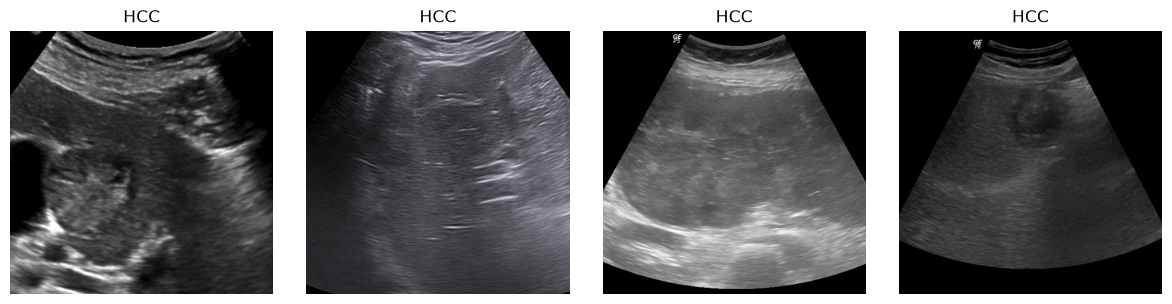

In [7]:
datasets = {split: SMCLUDDataset(DATASET_ROOT, split, config) for split in SPLITS}
split_summary = pd.DataFrame([
    {'split': split, 'records': len(dataset), 'labels': pd.Series([record.label for record in dataset.records]).value_counts().to_dict(), 'patients': len({record.patient_group_id for record in dataset.records})}
    for split, dataset in datasets.items()
])
display(split_summary)

loader = create_dataloader(DATASET_ROOT, 'val', config, batch_size=4, shuffle=False)
batch_images, batch_labels, batch_patients = next(iter(loader))
print({'batch_shape': tuple(batch_images.shape), 'labels': batch_labels.tolist(), 'patient_group_id': list(batch_patients), 'finite': bool(torch.isfinite(batch_images).all())})
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for axis, tensor, label in zip(axes, batch_images, batch_labels):
    view = tensor.permute(1, 2, 0).numpy()
    view = (view * torch.tensor(IMAGENET_STD).numpy()) + torch.tensor(IMAGENET_MEAN).numpy()
    axis.imshow(view.clip(0, 1))
    axis.set_title(LABELS[int(label)])
    axis.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
def md5(path):
    digest = hashlib.md5()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

metadata['destination_md5'] = metadata['path'].map(md5)
metadata['checksum_match'] = metadata['destination_md5'] == metadata['md5']
metadata['source_md5'] = metadata['source_path'].map(md5)
metadata['source_match'] = metadata['source_md5'] == metadata['md5']
patient_sets = {split: set(metadata.loc[metadata['split'] == split, 'patient_group_id']) for split in SPLITS}
leakage = {(left, right): len(patient_sets[left] & patient_sets[right]) for left, right in [('train', 'val'), ('train', 'test'), ('val', 'test')]}
assert len(metadata) == 2656 and len(invalid) == 0
assert metadata['checksum_match'].all() and metadata['source_match'].all()
assert all(value == 0 for value in leakage.values())
assert all(len(dataset) == expected for dataset, expected in zip(datasets.values(), [1770, 629, 257]))
print({'all_images': len(metadata), 'checksum_matches': int(metadata['checksum_match'].sum()), 'source_matches': int(metadata['source_match'].sum()), 'patient_leakage': leakage, 'source_files_modified': False})

{'all_images': 2656, 'checksum_matches': 2656, 'source_matches': 2656, 'patient_leakage': {('train', 'val'): 0, ('train', 'test'): 0, ('val', 'test'): 0}, 'source_files_modified': False}


: 

## Summary

The physical split remains unchanged and all 2,656 images are readable. Letterbox resizing preserves aspect ratio by padding instead of cropping; direct resizing changes geometry for non-square sources. ImageNet normalization is applied after deterministic RGB conversion and resizing. This notebook intentionally stops before augmentation or model training.